In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)

# Check whether a GPU is available
gpu_devices = tf.config.list_physical_devices("GPU")

if gpu_devices:
    print("GPU is available!")
    print(gpu_devices)
else:
    print("GPU is not available. We can still continue using the CPU.")

TensorFlow version: 2.21.0
NumPy version: 2.1.3
GPU is available!
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import os
import zipfile

# Find ZIP files uploaded to the Colab working directory
zip_files = [
    f for f in os.listdir("/content")
    if f.lower().endswith(".zip")
]

print("ZIP files found:", zip_files)

ZIP files found: ['archive.zip']


In [4]:
import os

print(os.listdir("/content"))

['.config', 'archive.zip', 'sample_data']


In [9]:
import os
import zipfile

print("Files:", os.listdir("/content"))

Files: ['.config', 'archive.zip', 'sample_data']


In [10]:
import os
import zipfile

zip_path = "/content/archive.zip"
extract_path = "/content/EcoTrack_Dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Dataset location:", extract_path)

Dataset extracted successfully!
Dataset location: /content/EcoTrack_Dataset


In [11]:
import os

dataset_path = "/content/EcoTrack_Dataset"

for root, dirs, files in os.walk(dataset_path):
    depth = root.replace(dataset_path, "").count(os.sep)

    if depth <= 3:
        print(
            "  " * depth,
            os.path.basename(root) or "EcoTrack_Dataset",
            f"({len(files)} files)"
        )

 EcoTrack_Dataset (0 files)
   dataset-resized (0 files)
     metal (410 files)
     glass (501 files)
     paper (594 files)
     plastic (482 files)
     trash (137 files)
     cardboard (403 files)


In [12]:
import os

dataset_dir = "/content/EcoTrack_Dataset/dataset-resized"

print("Dataset path exists:", os.path.exists(dataset_dir))
print("\nWaste categories:")

for category in sorted(os.listdir(dataset_dir)):
    category_path = os.path.join(dataset_dir, category)

    if os.path.isdir(category_path):
        print(category)

Dataset path exists: True

Waste categories:
cardboard
glass
metal
paper
plastic
trash


In [13]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    validation_split=0.30,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

remaining_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    validation_split=0.30,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

class_names = train_ds.class_names

print("\nClass names:", class_names)

# Split the remaining 30% equally into validation and test sets.
remaining_batches = tf.data.experimental.cardinality(remaining_ds).numpy()
test_batches = remaining_batches // 2

test_ds = remaining_ds.take(test_batches)
val_ds = remaining_ds.skip(test_batches)

print("\nDataset loaded successfully!")
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

Found 2527 files belonging to 6 classes.
Using 1769 files for training.
Found 2527 files belonging to 6 classes.
Using 758 files for validation.

Class names: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']

Dataset loaded successfully!
Training batches: 56
Validation batches: 12
Test batches: 12


##**Build the MobileNetV2 model**

**Prepare the images**

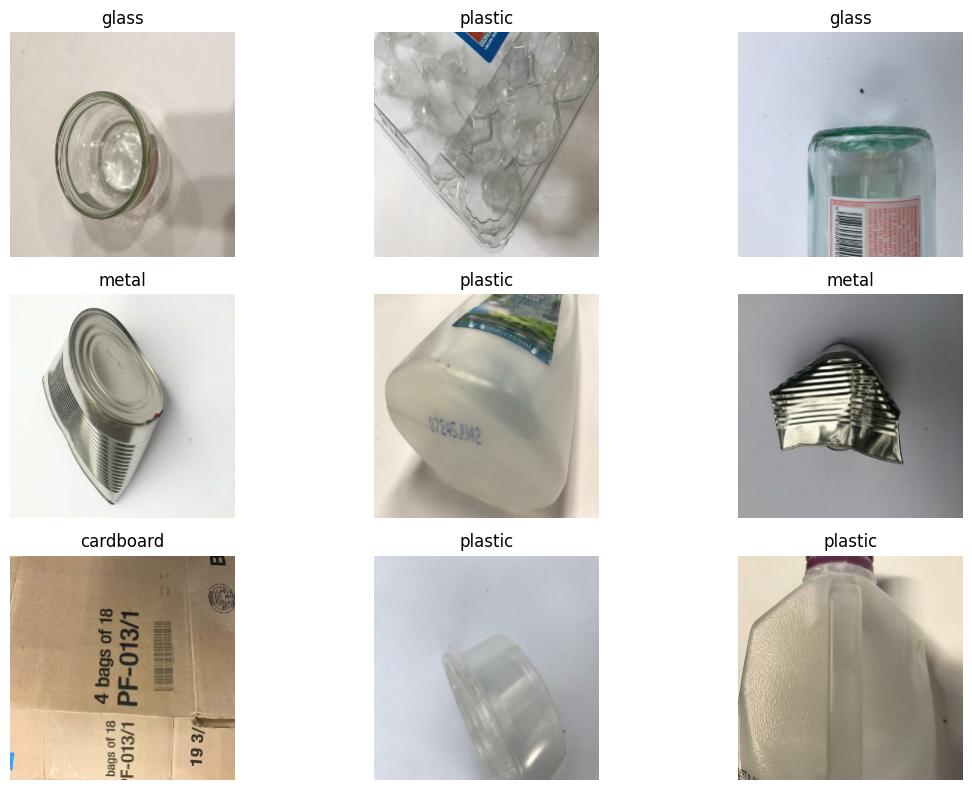

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [15]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

print("TensorFlow version:", tf.__version__)
print("Classes:", class_names)

TensorFlow version: 2.21.0
Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


In [16]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

AUTOTUNE = tf.data.AUTOTUNE

def preprocess_images(images, labels):
    images = preprocess_input(images)
    return images, labels

train_ds = train_ds.map(
    preprocess_images,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

val_ds = val_ds.map(
    preprocess_images,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

test_ds = test_ds.map(
    preprocess_images,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

print("Image preprocessing completed!")

Image preprocessing completed!


**Create the model**

In [17]:
num_classes = len(class_names)

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the pretrained layers initially.
base_model.trainable = False

model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Lambda(preprocess_input),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

#**Train the model**


In [18]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 26s 264ms/step - accuracy: 0.2125 - loss: 1.8837 - val_accuracy: 0.2781 - val_loss: 1.6921
Epoch 2/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - accuracy: 0.2595 - loss: 1.7650 - val_accuracy: 0.3235 - val_loss: 1.7104
Epoch 3/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - accuracy: 0.2708 - loss: 1.7130 - val_accuracy: 0.3128 - val_loss: 1.6261
Epoch 4/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - accuracy: 0.2747 - loss: 1.6902 - val_accuracy: 0.3262 - val_loss: 1.6009
Epoch 5/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 63ms/step - accuracy: 0.3222 - loss: 1.6337 - val_accuracy: 0.3342 - val_loss: 1.6055
Epoch 6/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 62ms/step - accuracy: 0.3064 - loss: 1.6293 - val_accuracy: 0.3636 - val_loss: 1.5434
Epoch 7/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - accuracy: 0.3369 - loss: 1.6013 - val_accuracy: 0.4011 - val_loss: 1.5487
Epoch 8/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 63ms/step - accuracy: 0.3132 - loss: 1.5947 - val_accuracy: 0.3636 -

##**Plot the training results**

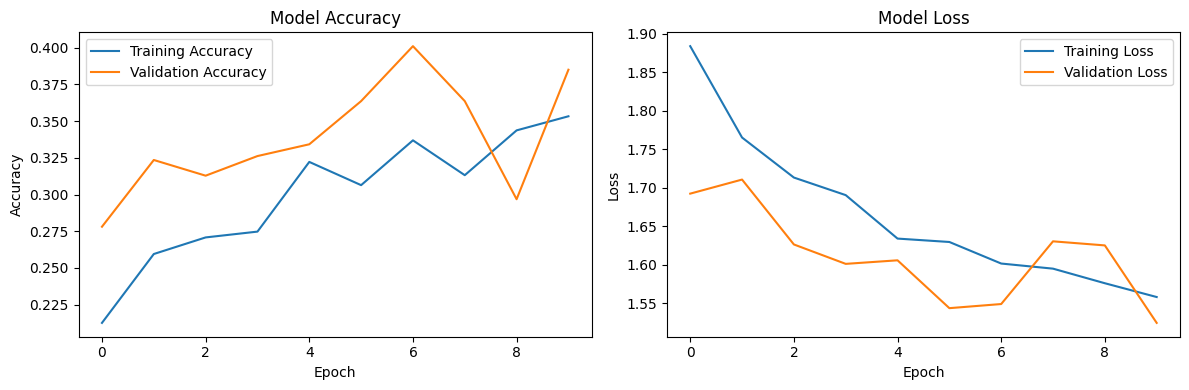

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

##**Train The Model**

In [20]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    validation_split=0.30,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

remaining_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    validation_split=0.30,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names

remaining_batches = tf.data.experimental.cardinality(remaining_ds).numpy()
test_batches = remaining_batches // 2

test_ds = remaining_ds.take(test_batches)
val_ds = remaining_ds.skip(test_batches)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Datasets are ready for training!")
print("Classes:", class_names)

Found 2527 files belonging to 6 classes.
Using 1769 files for training.
Found 2527 files belonging to 6 classes.
Using 758 files for validation.
Datasets are ready for training!
Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


In [21]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping]
)

Epoch 1/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 101ms/step - accuracy: 0.4924 - loss: 2.6006 - val_accuracy: 0.7139 - val_loss: 0.8348
Epoch 2/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 65ms/step - accuracy: 0.7422 - loss: 0.7824 - val_accuracy: 0.7299 - val_loss: 0.8249
Epoch 3/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 66ms/step - accuracy: 0.7716 - loss: 0.6302 - val_accuracy: 0.7914 - val_loss: 0.6067
Epoch 4/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - accuracy: 0.8151 - loss: 0.5133 - val_accuracy: 0.7861 - val_loss: 0.5893
Epoch 5/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 52ms/step - accuracy: 0.8253 - loss: 0.4784 - val_accuracy: 0.7941 - val_loss: 0.6046
Epoch 6/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 62ms/step - accuracy: 0.8491 - loss: 0.4014 - val_accuracy: 0.7914 - val_loss: 0.5640
Epoch 7/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step - accuracy: 0.8604 - loss: 0.3950 - val_accuracy: 0.8262 - val_loss: 0.4863
Epoch 8/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 58ms/step - accuracy: 0.8683 - loss: 0.3531 - val_accuracy: 0.8289 - 

**Save the trained model**

In [22]:
model.save("/content/ecotrack_waste_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [23]:
test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.8099 - loss: 0.5638
Test Loss: 0.5638
Test Accuracy: 80.99%


In [24]:
import numpy as np
from sklearn.metrics import classification_report

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

              precision    recall  f1-score   support

   cardboard       0.91      0.88      0.89        67
       glass       0.79      0.85      0.81        78
       metal       0.84      0.85      0.85        62
       paper       0.83      0.94      0.88        78
     plastic       0.86      0.72      0.79        76
       trash       0.65      0.57      0.60        23

    accuracy                           0.83       384
   macro avg       0.81      0.80      0.80       384
weighted avg       0.83      0.83      0.83       384



**Fix the evaluation and improve the model**

In [25]:
import os
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

dataset_dir = "/content/EcoTrack_Dataset/dataset-resized"

image_paths = []
image_labels = []

class_names = sorted([
    name for name in os.listdir(dataset_dir)
    if os.path.isdir(os.path.join(dataset_dir, name))
])

valid_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

for label, category in enumerate(class_names):
    category_dir = os.path.join(dataset_dir, category)

    for filename in os.listdir(category_dir):
        if filename.lower().endswith(valid_extensions):
            image_paths.append(
                os.path.join(category_dir, filename)
            )
            image_labels.append(label)

image_paths = np.array(image_paths)
image_labels = np.array(image_labels)

# 70% training, 30% remaining
X_train, X_remaining, y_train, y_remaining = train_test_split(
    image_paths,
    image_labels,
    test_size=0.30,
    random_state=42,
    stratify=image_labels
)

# Split the remaining 30% equally
X_val, X_test, y_val, y_test = train_test_split(
    X_remaining,
    y_remaining,
    test_size=0.50,
    random_state=42,
    stratify=y_remaining
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Test images:", len(X_test))
print("Classes:", class_names)

Training images: 1768
Validation images: 379
Test images: 380
Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


In [26]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    return image, label

def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            len(paths),
            seed=42,
            reshuffle_each_iteration=True
        )

    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds

train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

print("All datasets are ready!")

All datasets are ready!


In [27]:
#RETRAIN THE MODEL

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping]
)

Epoch 1/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 25s 335ms/step - accuracy: 0.8580 - loss: 0.3968 - val_accuracy: 0.8971 - val_loss: 0.3121
Epoch 2/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 22s 50ms/step - accuracy: 0.8682 - loss: 0.3628 - val_accuracy: 0.8892 - val_loss: 0.3169
Epoch 3/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - accuracy: 0.8767 - loss: 0.3303 - val_accuracy: 0.8892 - val_loss: 0.3136
Epoch 4/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - accuracy: 0.9010 - loss: 0.2932 - val_accuracy: 0.8865 - val_loss: 0.3252


In [28]:
from sklearn.metrics import classification_report, confusion_matrix

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

y_true = []
y_pred = []

for images, labels in test_ds:
    probabilities = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(probabilities, axis=1))

print(f"\nTest Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

12/12 ━━━━━━━━━━━━━━━━━━━━ 5s 426ms/step - accuracy: 0.9053 - loss: 0.2845

Test Accuracy: 90.53%
Test Loss: 0.2845

Classification Report:

              precision    recall  f1-score   support

   cardboard       0.98      0.92      0.95        60
       glass       0.90      0.86      0.88        76
       metal       0.95      0.94      0.94        62
       paper       0.90      0.97      0.93        89
     plastic       0.87      0.85      0.86        73
       trash       0.75      0.90      0.82        20

    accuracy                           0.91       380
   macro avg       0.89      0.90      0.90       380
weighted avg       0.91      0.91      0.91       380



In [29]:
import json
import os

model_path = "/content/ecotrack_waste_model.keras"
labels_path = "/content/ecotrack_class_names.json"

model.save(model_path)

with open(labels_path, "w") as f:
    json.dump(class_names, f)

print("Model saved:", model_path)
print("Class labels saved:", labels_path)
print("Classes:", class_names)

Model saved: /content/ecotrack_waste_model.keras
Class labels saved: /content/ecotrack_class_names.json
Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


# **Build the EcoTrack AI web application**

In [30]:
%pip install -q gradio

In [31]:
import numpy as np
import tensorflow as tf
import gradio as gr
from PIL import Image

IMG_SIZE = (224, 224)

# Recycling guidance for the six model classes
recycling_guidance = {
    "cardboard": (
        "Flatten the cardboard and keep it dry. "
        "Remove excessive tape or food contamination where practical. "
        "Check your local paper and cardboard recycling rules."
    ),
    "glass": (
        "Handle broken glass carefully. Separate reusable containers "
        "when appropriate and check whether your local service accepts "
        "glass bottles and jars."
    ),
    "metal": (
        "Empty the container and check local rules for metal cans "
        "and scrap metal. Sharp edges should be handled carefully."
    ),
    "paper": (
        "Keep paper clean and dry. Paper contaminated with food or grease "
        "may not be accepted in ordinary paper recycling."
    ),
    "plastic": (
        "Empty and rinse the container when practical. Check the item type "
        "and local recycling rules, because not all plastics are accepted."
    ),
    "trash": (
        "The model classified this image as general trash. This category "
        "does not identify the material precisely. Inspect the item and "
        "follow local waste disposal guidance."
    )
}

def predict_waste(image):
    if image is None:
        return {}, "Please upload an image first."

    # Convert the uploaded image into the format expected by the model.
    image = image.convert("RGB")
    image = image.resize(IMG_SIZE)

    image_array = np.array(image, dtype=np.float32)
    image_array = np.expand_dims(image_array, axis=0)

    # The model already contains MobileNetV2 preprocessing.
    probabilities = model.predict(image_array, verbose=0)[0]

    predicted_index = int(np.argmax(probabilities))
    predicted_category = class_names[predicted_index]
    confidence = float(probabilities[predicted_index])

    # Gradio Label displays the model's scores for each category.
    scores = {
        class_names[i]: float(probabilities[i])
        for i in range(len(class_names))
    }

    guidance = recycling_guidance.get(
        predicted_category,
        "Check your local waste disposal guidance."
    )

    result_text = (
        f"Predicted category: {predicted_category.title()}\n"
        f"Model confidence: {confidence * 100:.2f}%\n\n"
        f"Recycling guidance:\n{guidance}\n\n"
        "Note: This is an AI prediction, not a verified material "
        "identification. Confirm the item and local disposal rules."
    )

    return scores, result_text

print("EcoTrack AI prediction function is ready!")

EcoTrack AI prediction function is ready!


In [32]:
import gradio as gr

with gr.Blocks(title="EcoTrack AI") as demo:
    gr.Markdown(
        """
        # 🌱 EcoTrack AI
        ### Smart Waste Classification and Recycling Assistant

        Upload a picture of a waste item to predict its category
        and receive general recycling guidance.
        """
    )

    with gr.Row():
        with gr.Column():
            image_input = gr.Image(
                type="pil",
                label="Upload a waste image"
            )
            predict_button = gr.Button(
                "Classify Waste",
                variant="primary"
            )

        with gr.Column():
            prediction_output = gr.Label(
                num_top_classes=3,
                label="Waste Classification"
            )
            guidance_output = gr.Textbox(
                label="Recycling Guidance",
                lines=7
            )

    predict_button.click(
        fn=predict_waste,
        inputs=image_input,
        outputs=[prediction_output, guidance_output]
    )

    gr.Markdown(
        """
        **EcoTrack AI disclaimer:** Predictions may be incorrect.
        Check the item and follow local recycling regulations.
        """
    )

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4317197ff56227c47a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
